# Notebook 04 — Feature Selection

## Objective

To identify a compact and informative set of network traffic features
for DDoS detection.

### Feature selection strategy

1. Start with statistically significant features from Notebook 03.
2. Remove highly correlated/redundant features.
3. Use model-based feature importance to identify useful features.
4. Define the final feature set for subsequent model experiments.



In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [3]:
df = pd.read_csv("netguard_cleaned.csv")

print("Dataset shape:", df.shape)
print(df["Label"].value_counts())

Dataset shape: (223082, 79)
Label
DDoS      128014
BENIGN     95068
Name: count, dtype: int64


In [4]:
stats_df = pd.read_csv(
    "statistical_feature_analysis.csv"
)

print(stats_df.shape)
stats_df.head()

(78, 8)


,Feature,BENIGN_Median,DDoS_Median,P_Value,Adjusted_P_Value,Effect_Size,Abs_Effect_Size,Significant
0,Bwd Packet Length Min,6.0,0.000000,0.0,0.0,-0.593208,0.593208,True
1,Bwd Packet Length Std,0.0,2189.772933,0.0,0.0,0.509735,0.509735,True
2,Fwd IAT Std,0.0,932490.395650,0.0,0.0,0.505436,0.505436,True
3,Fwd Packet Length Max,42.0,20.000000,0.0,0.0,-0.494844,0.494844,True
4,Init_Win_bytes_forward,229.0,256.000000,0.0,0.0,0.492431,0.492431,True


In [5]:
significant_features = stats_df[
    stats_df["Significant"] == True
]["Feature"].tolist()

print("Number of statistically significant features:",
      len(significant_features))

print("\nFeatures:")
print(significant_features)

Number of statistically significant features: 68

Features:
['Bwd Packet Length Min', 'Bwd Packet Length Std', 'Fwd IAT Std', 'Fwd Packet Length Max', 'Init_Win_bytes_forward', 'Fwd Packet Length Mean', 'Avg Fwd Segment Size', 'act_data_pkt_fwd', 'Fwd IAT Max', 'Fwd IAT Mean', 'Fwd IAT Total', 'Subflow Fwd Packets', 'Total Fwd Packets', 'Fwd Packet Length Min', 'Subflow Fwd Bytes', 'Total Length of Fwd Packets', 'Flow IAT Std', 'Bwd Packets/s', 'Average Packet Size', 'Fwd Header Length', 'Fwd Header Length.1', 'Packet Length Mean', 'Min Packet Length', 'URG Flag Count', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Max', 'Avg Bwd Segment Size', 'Bwd Packet Length Mean', 'Bwd Packet Length Max', 'Packet Length Variance', 'Packet Length Std', 'Max Packet Length', 'Flow Duration', 'Fwd IAT Min', 'Subflow Bwd Bytes', 'Total Length of Bwd Packets', 'min_seg_size_forward', 'Down/Up Ratio', 'Destination Port', 'Fwd Packets/s', 'PSH Flag Count', 'Flow Bytes/s', 'Bwd IAT Total', 'Bwd IAT Max', '

## Removing Redundant Features

Two features may both be statistically significant but contain
very similar information.

For example:

Feature A → statistically significant
Feature B → statistically significant

If A and B are highly correlated, keeping both may add redundancy.

Therefore, highly correlated features will be examined before
final feature selection.

X_significant = df[significant_features]

correlation_matrix = X_significant.corr().abs()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title("Correlation Matrix of Significant Features")
plt.tight_layout()
plt.show()

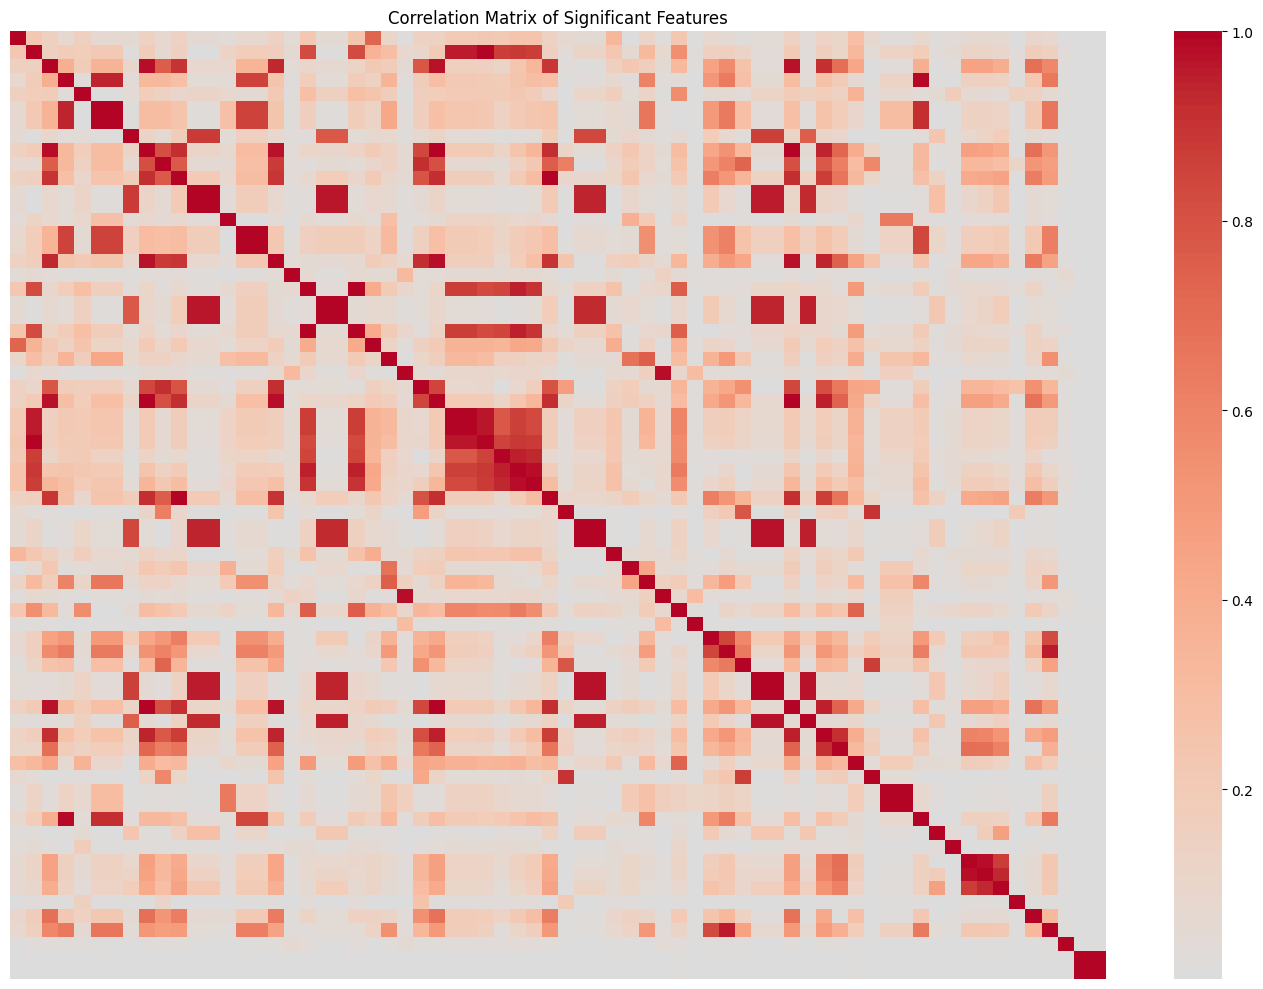

In [6]:
X_significant = df[significant_features]

correlation_matrix = X_significant.corr().abs()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title("Correlation Matrix of Significant Features")
plt.tight_layout()
plt.show()

In [7]:
threshold = 0.90

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = []

for column in upper_triangle.columns:

    for row in upper_triangle.index:

        correlation = upper_triangle.loc[row, column]

        if correlation > threshold:

            high_corr_pairs.append(
                (row, column, correlation)
            )

high_corr_pairs[:20]

[('Fwd Packet Length Max',
  'Fwd Packet Length Mean',
  np.float64(0.9409132905493096)),
 ('Fwd Packet Length Max',
  'Avg Fwd Segment Size',
  np.float64(0.9409132905493096)),
 ('Fwd Packet Length Mean', 'Avg Fwd Segment Size', np.float64(1.0)),
 ('Fwd IAT Std', 'Fwd IAT Max', np.float64(0.9804372726015166)),
 ('Fwd IAT Max', 'Fwd IAT Total', np.float64(0.9213060320720269)),
 ('Subflow Fwd Packets', 'Total Fwd Packets', np.float64(1.0)),
 ('Subflow Fwd Bytes', 'Total Length of Fwd Packets', np.float64(1.0)),
 ('Fwd IAT Std', 'Flow IAT Std', np.float64(0.935475983264425)),
 ('Fwd IAT Max', 'Flow IAT Std', np.float64(0.96923298371966)),
 ('Subflow Fwd Packets', 'Fwd Header Length', np.float64(0.9684385661726459)),
 ('Total Fwd Packets', 'Fwd Header Length', np.float64(0.9684385661726459)),
 ('Subflow Fwd Packets',
  'Fwd Header Length.1',
  np.float64(0.9684385661726459)),
 ('Total Fwd Packets', 'Fwd Header Length.1', np.float64(0.9684385661726459)),
 ('Fwd Header Length', 'Fwd Header 

In [8]:
print(
    "Number of highly correlated pairs:",
    len(high_corr_pairs)
)

Number of highly correlated pairs: 88


In [9]:
high_corr_df = pd.DataFrame(
    high_corr_pairs,
    columns=["Feature_1", "Feature_2", "Correlation"]
)

high_corr_df = high_corr_df.sort_values(
    "Correlation",
    ascending=False
)

high_corr_df.head(20)

,Feature_1,Feature_2,Correlation
23,Avg Bwd Segment Size,Bwd Packet Length Mean,1.000000
2,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000
6,Subflow Fwd Bytes,Total Length of Fwd Packets,1.000000
5,Subflow Fwd Packets,Total Fwd Packets,1.000000
13,Fwd Header Length,Fwd Header Length.1,1.000000
87,ECE Flag Count,RST Flag Count,1.000000
80,Fwd PSH Flags,SYN Flag Count,1.000000
44,Subflow Bwd Bytes,Total Length of Bwd Packets,1.000000
58,Subflow Bwd Packets,Total Backward Packets,1.000000
14,Average Packet Size,Packet Length Mean,0.999354


In [10]:
features_to_remove = set()

for feature1, feature2, correlation in high_corr_pairs:

    # Remove the second feature
    features_to_remove.add(feature2)

correlation_filtered_features = [
    feature for feature in significant_features
    if feature not in features_to_remove
]

print("Original significant features:",
      len(significant_features))

print("After correlation filtering:",
      len(correlation_filtered_features))

Original significant features: 68
After correlation filtering: 34


In [11]:
X = df[correlation_filtered_features]

y = df["Label"]

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)
print("X shape:", X.shape)

Classes: ['BENIGN' 'DDoS']
X shape: (223082, 34)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 178465
Testing samples : 44617


In [13]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
3,Fwd Packet Length Max,0.123978
19,Destination Port,0.114453
0,Bwd Packet Length Min,0.097611
4,Init_Win_bytes_forward,0.092600
9,Subflow Fwd Bytes,0.082135
5,act_data_pkt_fwd,0.077424
2,Fwd IAT Std,0.062091
6,Fwd IAT Mean,0.053615
7,Subflow Fwd Packets,0.045936
1,Bwd Packet Length Std,0.040989


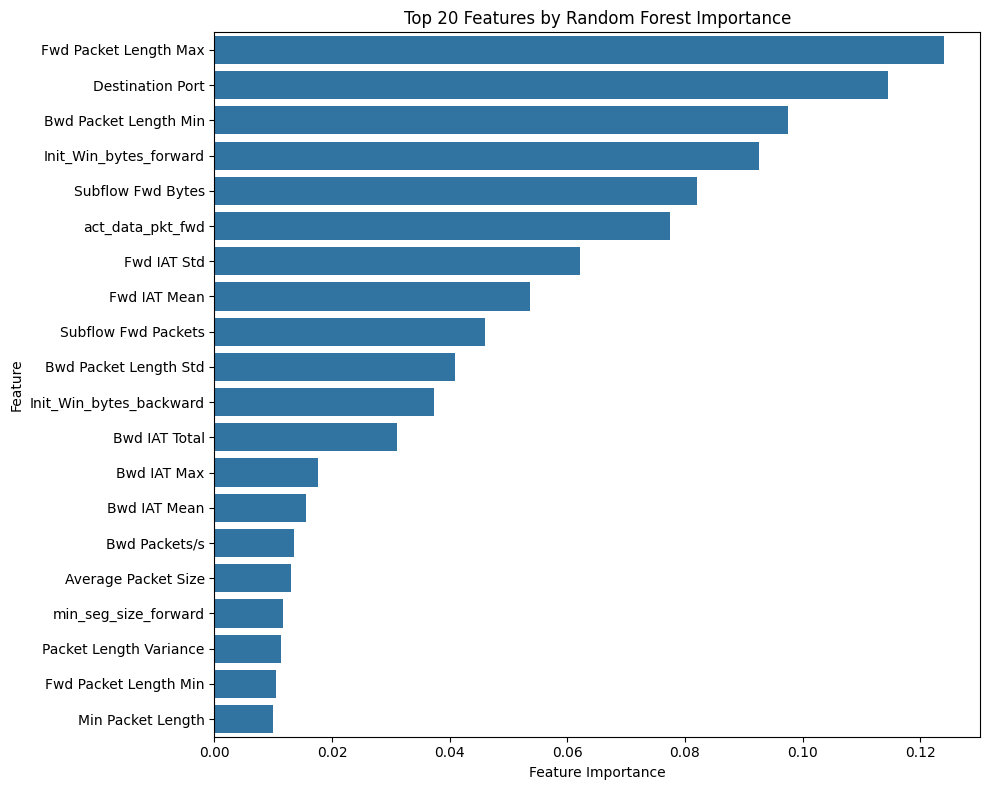

In [16]:
top_n = 20

top_importance = feature_importance.head(top_n)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_importance,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Features by Random Forest Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [17]:
selection_table = stats_df.merge(
    feature_importance,
    on="Feature",
    how="inner"
)

selection_table = selection_table.sort_values(
    "Importance",
    ascending=False
)

selection_table[
    [
        "Feature",
        "Adjusted_P_Value",
        "Abs_Effect_Size",
        "Importance"
    ]
].head(20)

,Feature,Adjusted_P_Value,Abs_Effect_Size,Importance
3,Fwd Packet Length Max,0.000000e+00,0.494844,0.123978
19,Destination Port,0.000000e+00,0.261726,0.114453
0,Bwd Packet Length Min,0.000000e+00,0.593208,0.097611
4,Init_Win_bytes_forward,0.000000e+00,0.492431,0.092600
9,Subflow Fwd Bytes,0.000000e+00,0.373922,0.082135
5,act_data_pkt_fwd,0.000000e+00,0.474326,0.077424
2,Fwd IAT Std,0.000000e+00,0.505436,0.062091
6,Fwd IAT Mean,0.000000e+00,0.468183,0.053615
7,Subflow Fwd Packets,0.000000e+00,0.409684,0.045936
1,Bwd Packet Length Std,0.000000e+00,0.509735,0.040989


In [18]:
final_features = (
    selection_table
    .sort_values("Importance", ascending=False)
    .head(20)["Feature"]
    .tolist()
)

print("Final selected features:")
for i, feature in enumerate(final_features, 1):
    print(f"{i}. {feature}")

Final selected features:
1. Fwd Packet Length Max
2. Destination Port
3. Bwd Packet Length Min
4. Init_Win_bytes_forward
5. Subflow Fwd Bytes
6. act_data_pkt_fwd
7. Fwd IAT Std
8. Fwd IAT Mean
9. Subflow Fwd Packets
10. Bwd Packet Length Std
11. Init_Win_bytes_backward
12. Bwd IAT Total
13. Bwd IAT Max
14. Bwd IAT Mean
15. Bwd Packets/s
16. Average Packet Size
17. min_seg_size_forward
18. Packet Length Variance
19. Fwd Packet Length Min
20. Min Packet Length


In [19]:
final_features_df = pd.DataFrame({
    "Feature": final_features
})

final_features_df.to_csv(
    "final_selected_features.csv",
    index=False
)

print("Final feature list saved.")

Final feature list saved.


In [20]:
selected_data = df[
    final_features + ["Label"]
]

print("Original dataset shape:", df.shape)
print("Selected dataset shape:", selected_data.shape)

Original dataset shape: (223082, 79)
Selected dataset shape: (223082, 21)


In [21]:
selected_data.to_csv(
    "netguard_selected_features.csv",
    index=False
)

print("Reduced dataset saved.")

Reduced dataset saved.


# Conclusion

Feature selection was performed using multiple sources of evidence.

### Stage 1 — Statistical evidence

The Mann–Whitney U test identified features that were statistically
different between BENIGN and DDoS traffic.

### Stage 2 — Redundancy analysis

Highly correlated features were identified and redundant features
were removed.

### Stage 3 — Model-based selection

Random Forest feature importance was used to identify features that
contribute strongly to predictive classification.

### Final outcome

A reduced set of network traffic features was selected for subsequent
machine-learning experiments.

The selected features will be used consistently in the later model
comparison experiments.